## Compute KE spectra in the simulation with rotated velocities 

In [1]:
import MITgcmutils as mit
import os
from matplotlib import pyplot as plt
import pandas as pd
import pickle
from scipy.interpolate import interp2d
import numpy as np
from scipy.interpolate import griddata
from scipy.optimize import curve_fit
from math import sin, cos, sqrt, atan2, radians
from datetime import datetime, timedelta

In [18]:
# # # Gulf Stream extension
# with open('/home/xihanz/my-jupyter-notebooks/GSExtension_reselect_sim.pkl', 'rb') as f:
#     data = pickle.load(f)
# # ssha_tot_combined = data['ssha_tot_combined']

In [2]:
# # Sargasso Sea (Oleander)
with open('/home/xihanz/my-jupyter-notebooks/Oleander_reselect_sim.pkl', 'rb') as f:
    data = pickle.load(f)
# ssha_tot_combined = data['ssha_tot_combined']

In [3]:
spectra_tot_combined = data['spectra_tot_combined']
ssha_tot_combined = data['ssha_tot_combined']
lon_strip_tot = data['lon_strip_tot']
lat_strip_tot = data['lat_strip_tot']
ssha_mean2side = data['ssha_mean2side']

In [4]:
ssha_tot_combined['dates'] = pd.to_datetime(ssha_tot_combined['dates'], format='%y/%m/%d')
ssha_tot_combined['day_of_year'] = ssha_tot_combined['dates'].dt.dayofyear

In [6]:
path="/resnick/groups/oceanphysics/albion/NA/run"
os.chdir(path)

In [7]:
xc = mit.rdmds('XC') # (800,2960)
yc = mit.rdmds('YC')
x = xc[0,:] # (2960,)
y = yc[:,0]

In [8]:
max_lat = np.max([np.max(arr) for arr in lat_strip_tot])
min_lat = np.min([np.min(arr) for arr in lat_strip_tot])
max_lon = np.max([np.max(arr) for arr in lon_strip_tot])
min_lon = np.min([np.min(arr) for arr in lon_strip_tot])

x_west = min_lon - 360
x_east = max_lon - 360
y_north = max_lat
y_south = min_lat

x_west_indx = np.argmin(np.abs(x - x_west))
x_east_indx = np.argmin(np.abs(x - x_east))
y_north_indx = np.argmin(np.abs(y-y_north))
y_south_indx = np.argmin(np.abs(y-y_south))

xc_region = xc[y_south_indx:y_north_indx,x_west_indx:x_east_indx]
yc_region = yc[y_south_indx:y_north_indx,x_west_indx:x_east_indx]

In [9]:
hacc = mit.rdmds('hFacC')
hfacw = mit.rdmds('hFacW')
hfacs = mit.rdmds('hFacS')

In [10]:
filenub0 = 7073572
ts = 45
file_index = filenub0 + ts * 1500

In [11]:
xc_region.shape[1]

425

### Daily averaged velocities

In [13]:
# daily-mean velocities 
n_days = 365  # Number of days in the dataset (you have 8808 hourly snapshots for 367 days)

uregion_daily = np.zeros((n_days, xc_region.shape[0], xc_region.shape[1]))  # Shape for daily averages (367, 300, 518)
vregion_daily = np.zeros((n_days, xc_region.shape[0], xc_region.shape[1]))
for day in range(n_days):
    dailymean_u = np.zeros((xc_region.shape[0], xc_region.shape[1]))
    dailymean_v = np.zeros((xc_region.shape[0], xc_region.shape[1]))
    for hour in range(24):
        file_index = filenub0 + (day * 24 + hour) * ts
        interior = mit.rdmds('diags/interior', file_index)
        uvel_region = interior[2, y_south_indx:y_north_indx,x_west_indx:x_east_indx]  # Extract SSH for the current hour
        vvel_region = interior[3, y_south_indx:y_north_indx,x_west_indx:x_east_indx] 
        uvel_region[hfacw[0,y_south_indx:y_north_indx,x_west_indx:x_east_indx]==0] = np.nan
        vvel_region[hfacs[0,y_south_indx:y_north_indx,x_west_indx:x_east_indx]==0] = np.nan
        # Accumulate velocity for this day
        dailymean_u += uvel_region
        dailymean_v += vvel_region

    uregion_daily[day,:,:] = dailymean_u/24
    vregion_daily[day,:,:] = dailymean_v/24

### Snapshots Velocities

In [15]:
# # snapshots
# n_days = 365  # Number of days in the dataset (you have 8808 hourly snapshots for 367 days)

# uregion_daily = np.zeros((n_days, xc_region.shape[0], xc_region.shape[1]))  # Shape for daily averages (367, 800, 2960)
# vregion_daily = np.zeros((n_days, xc_region.shape[0], xc_region.shape[1]))
# hour = 10
# for day in range(n_days):
#     # print(day)
#     dailymean_u = np.zeros((xc_region.shape[0], xc_region.shape[1]))
#     dailymean_v = np.zeros((xc_region.shape[0], xc_region.shape[1]))
#     # for hour in range(24):
#     file_index = filenub0 + (day * 24 + hour) * ts
#     interior = mit.rdmds('diags/interior', file_index)
#     uvel_region = interior[2, y_south_indx:y_north_indx,x_west_indx:x_east_indx]  # Extract SSH for the current hour
#     vvel_region = interior[3, y_south_indx:y_north_indx,x_west_indx:x_east_indx] 
#     uvel_region[hfacw[0,y_south_indx:y_north_indx,x_west_indx:x_east_indx]==0] = np.nan
#     vvel_region[hfacs[0,y_south_indx:y_north_indx,x_west_indx:x_east_indx]==0] = np.nan
#     # Accumulate velocity for this day
#     # dailymean_u += uvel_region
#     # dailymean_v += vvel_region

#     uregion_daily[day,:,:] = uvel_region
#     vregion_daily[day,:,:] = vvel_region

In [16]:
# start_dt = datetime(2025, 12, 6, 14,29)   # the true time of filenub0
# dates = []  # date label for each daily mean
# hour = 10
# for day in range(n_days):
#     # print(day)
#     it = filenub0 + (day*24 + hour)*ts
#     # Each 24h window runs 14:00 → 13:00, so it mostly belongs to the NEXT calendar day.
#     dates.append((start_dt + timedelta(days=day+1)).date())
# # Rotate so January data comes first and December last.
# # Find the first Jan 1 in the labels and roll so that index becomes 0.
# jan1_idx = next(i for i, d in enumerate(dates) if d.month == 1 and d.day == 1)
# dates = dates[jan1_idx:] + dates[:jan1_idx] 

In [17]:
# # jan1_idx = next(i for i, d in enumerate(dates) if d.month == 1 and d.day == 1)
# uregion_daily = np.roll(uregion_daily, -jan1_idx, axis=0)
# vregion_daily = np.roll(vregion_daily, -jan1_idx, axis=0)

In [17]:
# # save daily averaged velocities 
# d = {'uregion_daily_GS':uregion_daily,'vregion_daily_GS':vregion_daily}
# np.save('/home/xihanz/my-jupyter-notebooks/regional_velocities.npy', d,allow_pickle=True)

# d = {'uregion_daily_Ol':uregion_daily,'vregion_daily_Ol':vregion_daily}
# np.save('/home/xihanz/my-jupyter-notebooks/regional_velocities_Ol.npy', d,allow_pickle=True)

In [15]:
# # load daily averaged velocities GS extension
# regionalvel = np.load('/home/xihanz/my-jupyter-notebooks/regional_velocities.npy',allow_pickle='TRUE').item()
# for key, value in regionalvel.items():
#     globals()[key] = value

# load daily averaged velocities Oleander
regionalvel = np.load('/home/xihanz/my-jupyter-notebooks/regional_velocities_Ol.npy',allow_pickle='TRUE').item()
for key, value in regionalvel.items():
    globals()[key] = value

In [16]:
# velocity anomalies from time and spatial mean in simulation (regional)

anualmean_u = np.mean(uregion_daily_Ol,axis = 0)
anualmean_v = np.mean(vregion_daily_Ol,axis = 0)

uanom = uregion_daily_Ol - anualmean_u[None,:,:]
vanom = vregion_daily_Ol - anualmean_v[None,:,:]

u_spatialmean = np.nanmean(uanom,axis = tuple((1,2))) # Spatial average of selected region
v_spatialmean = np.nanmean(vanom,axis = tuple((1,2)))

u_spanom = uanom - u_spatialmean[:,None,None]
v_spanom = vanom - v_spatialmean[:,None,None] 

In [18]:
def model_spectra(ssh_reshaped_model,track_length,dx = 2e3):
    window = np.sqrt(8./3.)*np.sin(np.pi*np.arange(track_length)/track_length)**2
    window_2d = np.broadcast_to(window.reshape(track_length, 1), (track_length, 25))
    
    ssh_reshaped_model_left = ssh_reshaped_model[:,5:30]
    ssh_reshaped_model_right = ssh_reshaped_model[:,39:39+25]
    # if np.isnan(ssh_reshaped_model_left).any() and np.isnan(ssh_reshaped_model_right).any(): 
    #     print("error, recheck selection")
        # continue 
    results = []
    for oneswath in [ssh_reshaped_model_left,ssh_reshaped_model_right]:
        if np.all(np.isnan(oneswath)):
            print('nan swath')
            continue   # skip this array
        windowed_full = oneswath * window_2d
        amp_full = np.fft.rfft(windowed_full,axis=0)# rfft applied to windowed ssh [sample,y/2,x]
        ampsq_full = dx*(np.abs(amp_full))**2/track_length
        ampsq_1side_full = np.empty(ampsq_full.shape)
        ampsq_1side_full[:]=np.nan
        ampsq_1side_full[1:,:]=2*ampsq_full[1:,:]
        ampsq_1side_full[0,:] = ampsq_full[0,:]
        result = np.nanmean(ampsq_1side_full,axis = 1)#axis=tuple([0,2]))
        results.append(result)
    spec_1side_full = np.mean(results, axis=0)
    return spec_1side_full

In [19]:
def swot_along_cross_unit_vectors(lon, lat):
    """
    lon, lat shape: (along_track, cross_track)

    Returns:
        e_along, n_along, e_cross, n_cross
    where e = east component, n = north component.
    """
    R = 6371e3
    lon_rad = np.deg2rad(lon)
    lat_rad = np.deg2rad(lat)
    # avoid jump near dateline
    lon_rad = np.unwrap(lon_rad, axis=0)
    lon_rad = np.unwrap(lon_rad, axis=1)
    # along-track direction: increasing along-track index, axis=0
    dlon_along = np.gradient(lon_rad, axis=0)
    dlat_along = np.gradient(lat_rad, axis=0)
    east_along = R * np.cos(lat_rad) * dlon_along
    north_along = R * dlat_along
    norm_along = np.sqrt(east_along**2 + north_along**2)
    e_along = east_along / norm_along
    n_along = north_along / norm_along
    # cross-track direction: increasing cross-track index, axis=1
    dlon_cross = np.gradient(lon_rad, axis=1)
    dlat_cross = np.gradient(lat_rad, axis=1)
    east_cross = R * np.cos(lat_rad) * dlon_cross
    north_cross = R * dlat_cross
    norm_cross = np.sqrt(east_cross**2 + north_cross**2)
    e_cross = east_cross / norm_cross
    n_cross = north_cross / norm_cross
    return e_along, n_along, e_cross, n_cross

In [20]:
track_length = lon_strip_tot[0].shape[0]
u_along_spectra_sim = np.zeros((ssha_tot_combined.shape[0], track_length // 2 + 1))
v_cross_spectra_sim = np.zeros((ssha_tot_combined.shape[0], track_length // 2 + 1))

u_along_tot = np.zeros((ssha_tot_combined.shape[0], track_length,69))
v_cross_tot = np.zeros((ssha_tot_combined.shape[0], track_length,69))

for i, row in ssha_tot_combined.iterrows():
    print(i)

    dayofyear = row["day_of_year"]
    if dayofyear >= 366:
        continue

    day_indx = int(row["day_indx"])

    ssha2side_swot = row["ssha2side"] # SWOT ssh 
    lon_swot = lon_strip_tot[day_indx] - 360
    lat_swot = lat_strip_tot[day_indx]

    u_snap = np.squeeze(u_spanom[dayofyear - 1, :, :]) # simulation velocity u
    v_snap = np.squeeze(v_spanom[dayofyear - 1, :, :]) # simulation velocity v

    # u_snap = np.squeeze(uregion_daily_GS[dayofyear - 1, :, :]) # simulation velocity u
    # v_snap = np.squeeze(vregion_daily_GS[dayofyear - 1, :, :]) # simulation velocity v
    # u_snap = np.squeeze(uregion_daily_Ol[dayofyear - 1, :, :]) # simulation velocity u
    # v_snap = np.squeeze(vregion_daily_Ol[dayofyear - 1, :, :]) # simulation velocity v

    # interpolate simulation velocities to SWOT grids
    track_u = griddata((xc_region.flatten(), yc_region.flatten()), u_snap.flatten(),\
                       (lon_swot.flatten(), lat_swot.flatten()),method="linear")

    track_v = griddata((xc_region.flatten(), yc_region.flatten()),v_snap.flatten(),\
                       (lon_swot.flatten(), lat_swot.flatten()),method="linear")

    u_east = track_u.reshape(lon_swot.shape)
    v_north = track_v.reshape(lon_swot.shape)
    # compute direction vector at each point
    e_along, n_along, e_cross, n_cross = swot_along_cross_unit_vectors(lon_swot,lat_swot)
    # rotate simulation velocities
    u_along = u_east * e_along + v_north * n_along
    v_cross = u_east * e_cross + v_north * n_cross

    u_along[np.isnan(ssha2side_swot)] = np.nan
    v_cross[np.isnan(ssha2side_swot)] = np.nan

    u_along_tot[i,:,:] = u_along
    v_cross_tot[i,:,:] = v_cross

    u_along_spectra_sim[i, :] = model_spectra(u_along, track_length)
    v_cross_spectra_sim[i, :] = model_spectra(v_cross, track_length)

0
nan swath
nan swath
1
nan swath
nan swath
2
nan swath
nan swath
3
nan swath
nan swath
4
5
nan swath
nan swath
6
nan swath
nan swath
7
8
nan swath
nan swath
9
10
nan swath
nan swath
11
nan swath
nan swath
12
nan swath
nan swath
13
nan swath
nan swath
14
15
nan swath
nan swath
16
nan swath
nan swath
17
nan swath
nan swath
18
nan swath
nan swath
19
nan swath
nan swath
20
nan swath
nan swath
21
nan swath
nan swath
22
nan swath
nan swath
23
24
nan swath
nan swath
25
nan swath
nan swath
26
27
nan swath
nan swath
28
nan swath
nan swath
29
nan swath
nan swath
30
nan swath
nan swath
31
nan swath
nan swath
32
nan swath
nan swath
33
nan swath
nan swath
34
nan swath
nan swath
35
nan swath
nan swath
36
nan swath
nan swath
37
nan swath
nan swath
38
nan swath
nan swath
39
nan swath
nan swath
40
41
42
nan swath
nan swath
43
nan swath
nan swath
44
nan swath
nan swath
45
46
47
nan swath
nan swath
48
nan swath
nan swath
49
nan swath
nan swath
50
nan swath
nan swath
51
nan swath
nan swath
52
nan swath
n

In [21]:
ssha_tot_combined['u_along_tot'] = list(u_along_tot) # rotated simulation velocities 
ssha_tot_combined['v_cross_tot'] = list(v_cross_tot)

In [22]:
# geostrophic velocities computed from SSH
dx = 2e3  # meters
g = 9.81
ug_along_tot = np.zeros((ssha_tot_combined.shape[0], track_length,69)) # geostrophic velocities from simulation ssh (interoplated to SWOT grid)
vg_cross_tot = np.zeros((ssha_tot_combined.shape[0], track_length,69))

ug_along_spectra_sim = np.zeros((ssha_tot_combined.shape[0], track_length // 2 + 1))
vg_cross_spectra_sim = np.zeros((ssha_tot_combined.shape[0], track_length // 2 + 1))
for i, row in ssha_tot_combined.iterrows():
    print(i)

    dayofyear = row["day_of_year"]
    if dayofyear >= 366:
        continue

    day_indx = int(row["day_indx"])

    ssha2side = row['track_ssh_sim'] # simulation ssh in SWOT grid 
    lon_swot = lon_strip_tot[day_indx] - 360
    lat_swot = lat_strip_tot[day_indx]
    f = 2*np.pi*np.sin(2*np.pi*lat_swot/360)/(12*3600)
    fmean = np.nanmean(f)
    dssh_dalong = np.gradient(ssha2side, dx, axis=0)
    v_cross_geo = -(g / fmean) * dssh_dalong
    dssh_dcross = np.gradient(ssha2side, dx, axis=1)
    u_along_geo = (g / fmean) * dssh_dcross
    
    u_along_geo[np.isnan(ssha2side)] = np.nan
    v_cross_geo[np.isnan(ssha2side)] = np.nan

    ug_along_tot[i,:,:] = u_along_geo
    vg_cross_tot[i,:,:] = v_cross_geo

    ug_along_spectra_sim[i, :] = model_spectra(u_along_geo, track_length)
    vg_cross_spectra_sim[i, :] = model_spectra(v_cross_geo, track_length)

0
nan swath
nan swath
1
nan swath
nan swath
2
nan swath
nan swath
3
nan swath
nan swath
4
5
nan swath
nan swath
6
nan swath
nan swath
7
8
nan swath
nan swath
9
10
nan swath
nan swath
11
nan swath
nan swath
12
nan swath
nan swath
13
nan swath
nan swath
14
15
nan swath
nan swath
16
nan swath
nan swath
17
nan swath
nan swath
18
nan swath
nan swath
19
nan swath
nan swath
20
nan swath
nan swath
21
nan swath
nan swath
22
nan swath
nan swath
23
24
nan swath
nan swath
25
nan swath
nan swath
26
27
nan swath
nan swath
28
nan swath
nan swath
29
nan swath
nan swath
30
nan swath
nan swath
31
nan swath
nan swath
32
nan swath
nan swath
33
nan swath
nan swath
34
nan swath
nan swath
35
nan swath
nan swath
36
nan swath
nan swath
37
nan swath
nan swath
38
nan swath
nan swath
39
nan swath
nan swath
40
41
42
nan swath
nan swath
43
nan swath
nan swath
44
nan swath
nan swath
45
46
47
nan swath
nan swath
48
nan swath
nan swath
49
nan swath
nan swath
50
nan swath
nan swath
51
nan swath
nan swath
52
nan swath
n

In [24]:
ssha_tot_combined['ug_along_tot'] = list(ug_along_tot)
ssha_tot_combined['vg_cross_tot'] = list(vg_cross_tot)

In [25]:
ssha_tot_combined['ug_along_spectra_sim'] = list(ug_along_spectra_sim)
ssha_tot_combined['vg_cross_spectra_sim'] = list(vg_cross_spectra_sim)

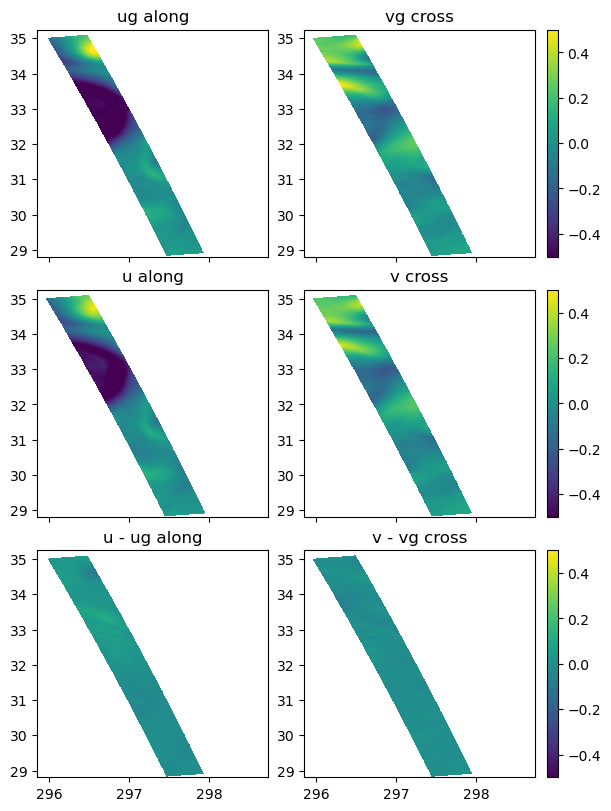

In [31]:
fig, ax = plt.subplots(3, 2, sharex=True, sharey=False, figsize=(6, 8), constrained_layout=True)
ax[0, 0].sharey(ax[0, 1])
ax[0, 0].pcolormesh(lon_strip_tot[1],lat_strip_tot[1],df1['ug_along_tot'].values[0],vmin = -0.5,vmax = 0.5)
ax[0, 0].set_title('ug along')


im = ax[0, 1].pcolormesh(lon_strip_tot[1],lat_strip_tot[1],df1['vg_cross_tot'].values[0],vmin = -0.5,vmax = 0.5)
ax[0, 1].set_title('vg cross')
plt.colorbar(im)


ax[1, 0].pcolormesh(lon_strip_tot[1],lat_strip_tot[1],df1['u_along_tot'].values[0],vmin = -0.5,vmax = 0.5)
ax[1, 0].set_title('u along')

im1 = ax[1, 1].pcolormesh(lon_strip_tot[1],lat_strip_tot[1],df1['v_cross_tot'].values[0],vmin = -0.5,vmax = 0.5)
ax[1, 1].set_title('v cross')
plt.colorbar(im1)

ax[2, 0].pcolormesh(lon_strip_tot[1],lat_strip_tot[1],df1['u_along_tot'].values[0]-df1['ug_along_tot'].values[0],vmin = -0.5,vmax = 0.5)
ax[2, 0].set_title('u - ug along')

im2 = ax[2, 1].pcolormesh(lon_strip_tot[1],lat_strip_tot[1],df1['v_cross_tot'].values[0]-df1['vg_cross_tot'].values[0],vmin = -0.5,vmax = 0.5)
ax[2, 1].set_title('v - vg cross')
plt.colorbar(im2)
# plt.savefig('/home/xihanz/my-jupyter-notebooks/velocitycomp_GSextension.png')
# plt.savefig('/home/xihanz/my-jupyter-notebooks/velocitycomp_Sargasso.png')

### save for KE spectra (daily mean)

In [2]:
# # save for the GS extension region time-mean
# d = {'u_along_spectra_sim':u_along_spectra_sim,'v_cross_spectra_sim':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_GSextension_new_swath_reselect_rotate.npy', d)

# # save for the Oleander region time-mean
# d = {'u_along_spectra_sim':u_along_spectra_sim,'v_cross_spectra_sim':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_Oleander_new_swath_reselect_rotate.npy', d)

# # save for the GS extension region time-mean velocity anomalies 
# d = {'u_along_spectra_sim':u_along_spectra_sim,'v_cross_spectra_sim':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_GSextension_new_swath_reselect_rotate_anom.npy', d)

# # save for the Oleander region time-mean
# d = {'u_along_spectra_sim':u_along_spectra_sim,'v_cross_spectra_sim':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_Oleander_new_swath_reselect_rotate_anom.npy', d)

### save for KE spectra (snapshots)

In [32]:
# d = {'u_along_spectra_sim_sp':u_along_spectra_sim,'v_cross_spectra_sim_sp':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_GSextension_new_swath_reselect_snapshots_rotate.npy', d)

# d = {'u_along_spectra_sim_sp':u_along_spectra_sim,'v_cross_spectra_sim_sp':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_Oleander_new_swath_reselect_snapshots_rotate.npy', d)

# # save for the GS extension region snapshot velocity anomalies 
# d = {'u_along_spectra_sim_sp':u_along_spectra_sim,'v_cross_spectra_sim_sp':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_GSextension_new_swath_reselect_snapshots_rotate_anom.npy', d)

# # save for the Oleander region snapshot velocity anomalies 
# d = {'u_along_spectra_sim_sp':u_along_spectra_sim,'v_cross_spectra_sim_sp':v_cross_spectra_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_Oleander_new_swath_reselect_snapshots_rotate_anom.npy', d)

### monthly fit for KE spectra

In [12]:
track_length = lon_strip_tot[0].shape[0]
dx = 2e3
k = np.fft.rfftfreq(track_length, dx)# rfft wave number cpm

In [13]:
# KEsimspectra_rotate = np.load('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_GSextension_new_swath_reselect_rotate_anom.npy',
#                               allow_pickle='TRUE').item()

KEsimspectra_rotate = np.load('/home/xihanz/my-jupyter-notebooks/KEsimdailymean_Oleander_new_swath_reselect_rotate_anom.npy',
                              allow_pickle='TRUE').item()
for key, value in KEsimspectra_rotate.items():
    globals()[key] = value

In [14]:
KEsimspectra_rotate.keys()

dict_keys(['u_along_spectra_sim', 'v_cross_spectra_sim'])

In [15]:
KE_spectra_sim = 0.5*v_cross_spectra_sim
ssha_tot_combined['KE_spectra_sim'] = list(KE_spectra_sim)

In [16]:
g = 9.8
f = np.mean(2*np.pi*np.sin(2*np.pi*yc_region/360)/(12*3600))

In [17]:
def balanced_ke(k, A, k0, s0):
    # return A * k**2 / (1.0 + (k / k0)**s0)
    return 0.5*g**2*(2*np.pi)**2*A * k**2 / (1.0 + (k / k0)**s0)/f**2

def F_balanced_ke(k, A, k0, s0):
    return np.log(balanced_ke(k, A, k0, s0))

In [20]:
k0init = 3e-6
s0init = 3
fitk = 35
ks = k[1:fitk]
KEs = KEmean[1:fitk]
Ainit = KEs[0]
p0 = [Ainit, k0init, s0init]

modelcoef, modelcov = curve_fit(F_balanced_ke,ks,np.log(KEs),p0=p0,sigma=np.sqrt(ks),absolute_sigma=False,
    bounds=([1e-20, 1e-20, 2],[1e9,   1e9,   20.0]),maxfev=20000)

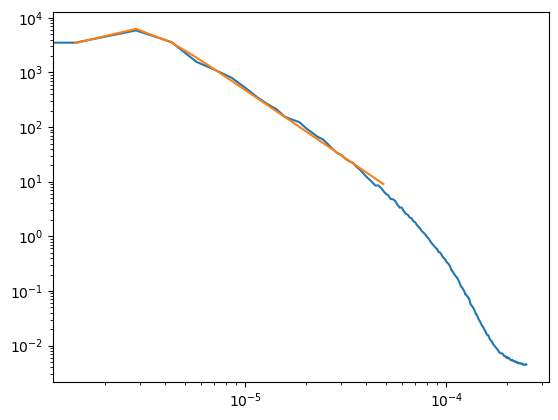

In [21]:
plt.loglog(k,KEmean)
plt.loglog(ks,balanced_ke(ks,*modelcoef))

In [22]:
monthly_mean_KE_simulation = ssha_tot_combined.groupby('month')['KE_spectra_sim'].apply(
    lambda x: np.mean(np.stack(x), axis = 0))

In [23]:
fitk = 35
slopemonthlyke_sim = np.empty((12,))
slopemonthlyke_sim[:] = np.nan 
unctmonthlyke_sim = np.empty((12,))
unctmonthlyke_sim[:] = np.nan
coefke_sim = np.empty((12,3))
coefke_sim[:] = np.nan
for month, spectrum in monthly_mean_KE_simulation.items():  
    # print(month)
    spec = spectrum[1:fitk]
    Ainit = spec[0]
    p0 = [Ainit, k0init, s0init]
    try:
        coef,covn = curve_fit(F_balanced_ke,k[1:fitk],np.log(spec),p0=p0,sigma=np.sqrt(k[1:fitk]),absolute_sigma=False,
            bounds=([1e-20, 1e-20, 2],[1e9,   1e9,   20.0]),maxfev=20000)
        slopemonthlyke_sim[int(month)-1] = coef[2] -2  #+ coef[3]
        unctmonthlyke_sim[int(month)-1] = np.sqrt(covn[2,2])
        coefke_sim[int(month)-1,:] = coef
        # print(coef)
    except Exception:
        continue  # Skip to the next iteration if curve_fit fails

### Save monthly KE spectral slope (daily mean, rotated, anomalies)

In [97]:
# d = {'slopemonthly_sp_sim_KE_GS':slopemonthlyke_sim}
# np.save('/home/xihanz/my-jupyter-notebooks/KEmonthlyslope.npy', d)

In [27]:
# d = np.load('/home/xihanz/my-jupyter-notebooks/KEmonthlyslope.npy', allow_pickle=True).item()
# d["slopemonthly_sp_sim_KE_Ol"] = slopemonthlyke_sim

In [28]:
# np.save('/home/xihanz/my-jupyter-notebooks/KEmonthlyslope.npy', d)